In [1]:
from pathlib import Path
import json
import zipfile
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 100)


In [2]:
from pathlib import Path

# Google Colab
PATH = Path("/content/data")

# Local
# PATH = Path("diplomacy-deception-detection/data/raw")

# Check dataset files
for file in ["train.jsonl", "validation.jsonl", "test.jsonl"]:
    print(file, ":", (PATH / file).exists())

train.jsonl : True
validation.jsonl : True
test.jsonl : True


Each line is a JSON object. inspect the structure before writing a general loader.

In [4]:
# Read the first record from training data
with open(PATH / "train.jsonl", "r", encoding="utf-8") as f:
    first_record = json.loads(f.readline())

# Explore the record
print("Fields:", list(first_record.keys()))
print("Game ID:", first_record["game_id"])
print("Conversation players:", first_record["players"])
print("Number of messages:", len(first_record["messages"]))
print("First message:", first_record["messages"][0])
print("Sender label:", first_record["sender_labels"][0])
print("Receiver label:", first_record["receiver_labels"][0])

Fields: ['messages', 'sender_labels', 'receiver_labels', 'speakers', 'receivers', 'absolute_message_index', 'relative_message_index', 'seasons', 'years', 'game_score', 'game_score_delta', 'players', 'game_id']
Game ID: 1
Conversation players: ['italy', 'germany']
Number of messages: 321
First message: Germany!

Just the person I want to speak with. I have a somewhat crazy idea that I’ve always wanted to try with I/G, but I’ve never actually convinced the other guy to try it. And, what’s worse, it might make you suspicious of me. 

So...do I suggest it?

I’m thinking that this is a low stakes game, not a tournament or anything, and an interesting and unusual move set might make it more fun? That’s my hope anyway.

What is your appetite like for unusual and crazy?
Sender label: True
Receiver label: True


In [5]:
# Understand the schema

schema_rows = []
for key, value in first_record.items():
    schema_rows.append({
        "field": key,
        "type": type(value).__name__,
        "length": len(value) if isinstance(value, list) else None,
        "example": str(value[0] if isinstance(value, list) and value else value)[:90]
    })
display(pd.DataFrame(schema_rows))


,field,type,length,example
0,messages,list,321.0,Germany!\n\nJust the person I want to speak with. I have a somewhat crazy idea that I’ve alw
1,sender_labels,list,321.0,True
2,receiver_labels,list,321.0,True
3,speakers,list,321.0,italy
4,receivers,list,321.0,germany
5,absolute_message_index,list,321.0,74
6,relative_message_index,list,321.0,0
7,seasons,list,321.0,Spring
8,years,list,321.0,1901
9,game_score,list,321.0,3


In [6]:
# Load All Three Datasets
def read_jsonl(path):
    records = []
    with Path(path).open("r", encoding="utf-8") as f:
        for line_number, line in enumerate(f, start=1):
            if not line.strip():
                continue
            try:
                records.append(json.loads(line))
            except json.JSONDecodeError as exc:
                raise ValueError(f"Invalid JSON in {path}, line {line_number}: {exc}") from exc
    return records


In [7]:
splits = {}

for split in ("train", "validation", "test"):
    splits[split] = read_jsonl(PATH / f"{split}.jsonl")
    print(f"{split}: {len(splits[split])} conversation records")

train: 189 conversation records
validation: 21 conversation records
test: 42 conversation records


In [8]:
# Calculate the number of conversations, games, and messages in each dataset split.
overview = []
for split, records in splits.items():
    overview.append({
        "split": split,
        "conversation_records": len(records),
        "games": len({r["game_id"] for r in records}),
        "messages": sum(len(r["messages"]) for r in records),
        "empty_conversations": sum(len(r["messages"]) == 0 for r in records)
    })

overview_df = pd.DataFrame(overview)
display(overview_df)
print("Total messages:", overview_df["messages"].sum())
print("Total games:", len({r["game_id"] for records in splits.values() for r in records}))


,split,conversation_records,games,messages,empty_conversations
0,train,189,9,13132,5
1,validation,21,1,1416,1
2,test,42,2,2741,0


Total messages: 17289
Total games: 12


In [ ]:
# Verify that every message has corresponding information, such as its sender, receiver, labels and game metadata
message_fields = [
    "messages", "sender_labels", "receiver_labels", "speakers", "receivers",
    "absolute_message_index", "relative_message_index", "seasons", "years",
    "game_score", "game_score_delta"
]
alignment_issues = []
for split, records in splits.items():
    for conversation_index, record in enumerate(records):
        lengths = {field: len(record[field]) for field in message_fields}
        if len(set(lengths.values())) != 1:
            alignment_issues.append({
                "split": split, "conversation_index": conversation_index,
                "game_id": record["game_id"], "lengths": lengths
            })

print("Conversations with inconsistent array lengths:", len(alignment_issues))
if alignment_issues:
    display(pd.DataFrame(alignment_issues).head())


In [9]:
# onvert the original JSONL data into a structured table where each row represents one message
rows = []
for split, records in splits.items():
    for conversation_index, record in enumerate(records):
        for i, message in enumerate(record["messages"]):
            rows.append({
                "split": split,
                "game_id": record["game_id"],
                "conversation_index": conversation_index,
                "message_position": i,
                "message": message,
                "speaker": record["speakers"][i],
                "receiver": record["receivers"][i],
                "sender_label": record["sender_labels"][i],
                "receiver_label": record["receiver_labels"][i],
                "absolute_message_index": record["absolute_message_index"][i],
                "relative_message_index": record["relative_message_index"][i],
                "season": record["seasons"][i],
                "year": record["years"][i],
                "game_score": record["game_score"][i],
                "score_delta": record["game_score_delta"][i],
                "players": record["players"],
            })

df = pd.DataFrame(rows)
print("DataFrame shape:", df.shape)
display(df.head(5))


DataFrame shape: (17289, 16)


,split,game_id,conversation_index,message_position,message,speaker,receiver,sender_label,receiver_label,absolute_message_index,relative_message_index,season,year,game_score,score_delta,players
0,train,1,0,0,Germany!\n\nJust the person I want to speak with. I have a somewhat crazy idea that I’ve always ...,italy,germany,True,True,74,0,Spring,1901,3,0,"[italy, germany]"
1,train,1,0,1,"You've whet my appetite, Italy. What's the suggestion?",germany,italy,True,True,76,1,Spring,1901,3,0,"[italy, germany]"
2,train,1,0,2,👍,italy,germany,True,True,86,2,Spring,1901,3,0,"[italy, germany]"
3,train,1,0,3,It seems like there are a lot of ways that could go wrong...I don't see why France would see you...,germany,italy,True,True,87,3,Spring,1901,3,0,"[italy, germany]"
4,train,1,0,4,"Yeah, I can’t say I’ve tried it and it works, cause I’ve never tried it or seen it. But how I th...",italy,germany,True,NOANNOTATION,89,4,Spring,1901,3,0,"[italy, germany]"


In [11]:
print("Sender labels:")
display(df["sender_label"].value_counts(dropna=False).rename_axis("label").reset_index(name="count"))


Sender labels:


,label,count
0,True,16402
1,False,887


In [12]:
print("Receiver labels:")
display(df["receiver_label"].value_counts(dropna=False).rename_axis("label").reset_index(name="count"))


Receiver labels:


,label,count
0,True,15005
1,NOANNOTATION,1506
2,False,778


In [14]:
# Measure the number of words and characters in each message
df["word_count"] = df["message"].str.split().str.len()
df["character_count"] = df["message"].str.len()

display(df[["word_count", "character_count"]].describe().round(2))


,word_count,character_count
count,17289.00,17289.00
mean,20.35,105.08
std,21.49,112.82
min,1.00,1.00
25%,7.00,35.00
50%,14.00,71.00
75%,26.00,135.00
max,294.00,1556.00


In [15]:
display(df.groupby("split")[["word_count", "character_count"]].agg(["mean", "median", "max"]).round(2))


word_count             character_count             
                 mean median  max            mean median   max
split                                                         
test            19.46   14.0  213           99.12   71.0  1018
train           20.79   14.0  294          107.51   71.0  1556
validation      18.02   14.0  222           94.03   72.0  1096

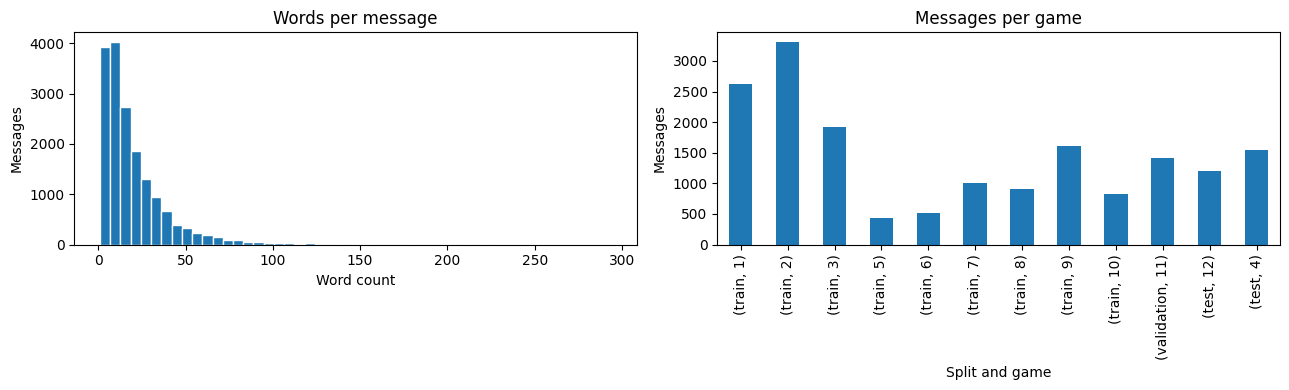

In [16]:
# message lengths and messages per game
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(df["word_count"], bins=50, edgecolor="white")
axes[0].set(title="Words per message", xlabel="Word count", ylabel="Messages")
per_game = df.groupby(["split", "game_id"], sort=False).size()
per_game.plot(kind="bar", ax=axes[1])
axes[1].set(title="Messages per game", xlabel="Split and game", ylabel="Messages")
plt.tight_layout()
plt.show()


#### Explore speakers and receivers

In [17]:
print("Most active speaker roles:")
display(df["speaker"].value_counts().head(10).to_frame("messages_sent"))


Most active speaker roles:


,messages_sent
speaker,
germany,3125
italy,2882
england,2658
austria,2275
russia,2211
france,2207
turkey,1931


In [18]:
print("Most common receiver roles:")
display(df["receiver"].value_counts().head(10).to_frame("messages_received"))


Most common receiver roles:


,messages_received
receiver,
germany,3336
england,2705
italy,2684
austria,2371
russia,2210
france,2037
turkey,1946


In [19]:
print("Unique speaker country roles:", df["speaker"].nunique())
print("Unique receiver country roles:", df["receiver"].nunique())


Unique speaker country roles: 7
Unique receiver country roles: 7


#### Explore a Sample Conversation

In [20]:
example = next(r for r in splits["train"] if r["messages"])
example_rows = []
for i, message in enumerate(example["messages"][:6]):
    example_rows.append({
        "position": i,
        "speaker": example["speakers"][i],
        "receiver": example["receivers"][i],
        "sender_label": example["sender_labels"][i],
        "receiver_label": example["receiver_labels"][i],
        "message": message
    })
print("Game:", example["game_id"], "| Players:", example["players"])



Game: 1 | Players: ['italy', 'germany']


In [21]:
display(pd.DataFrame(example_rows))

,position,speaker,receiver,sender_label,receiver_label,message
0,0,italy,germany,True,True,Germany!\n\nJust the person I want to speak with. I have a somewhat crazy idea that I’ve always ...
1,1,germany,italy,True,True,"You've whet my appetite, Italy. What's the suggestion?"
2,2,italy,germany,True,True,👍
3,3,germany,italy,True,True,It seems like there are a lot of ways that could go wrong...I don't see why France would see you...
4,4,italy,germany,True,NOANNOTATION,"Yeah, I can’t say I’ve tried it and it works, cause I’ve never tried it or seen it. But how I th..."
5,5,italy,germany,True,NOANNOTATION,"I am just sensing that you don’t like this idea, so shall we talk about something else? That was..."
